Saved comparison.png
A baseline
  goodput/s  baseline phase: 2.0
  goodput/s  spike phase   : 98.4
  goodput/s  post phase    : 6.75
  total 200s: 24447  timeouts: 12255  429s: 0
  recovery time after spike (s): 0
B protected
  goodput/s  baseline phase: 2.0
  goodput/s  spike phase   : 160.22
  goodput/s  post phase    : 6.68
  total 200s: 39274  timeouts: 3712  429s: 2747
  recovery time after spike (s): 0


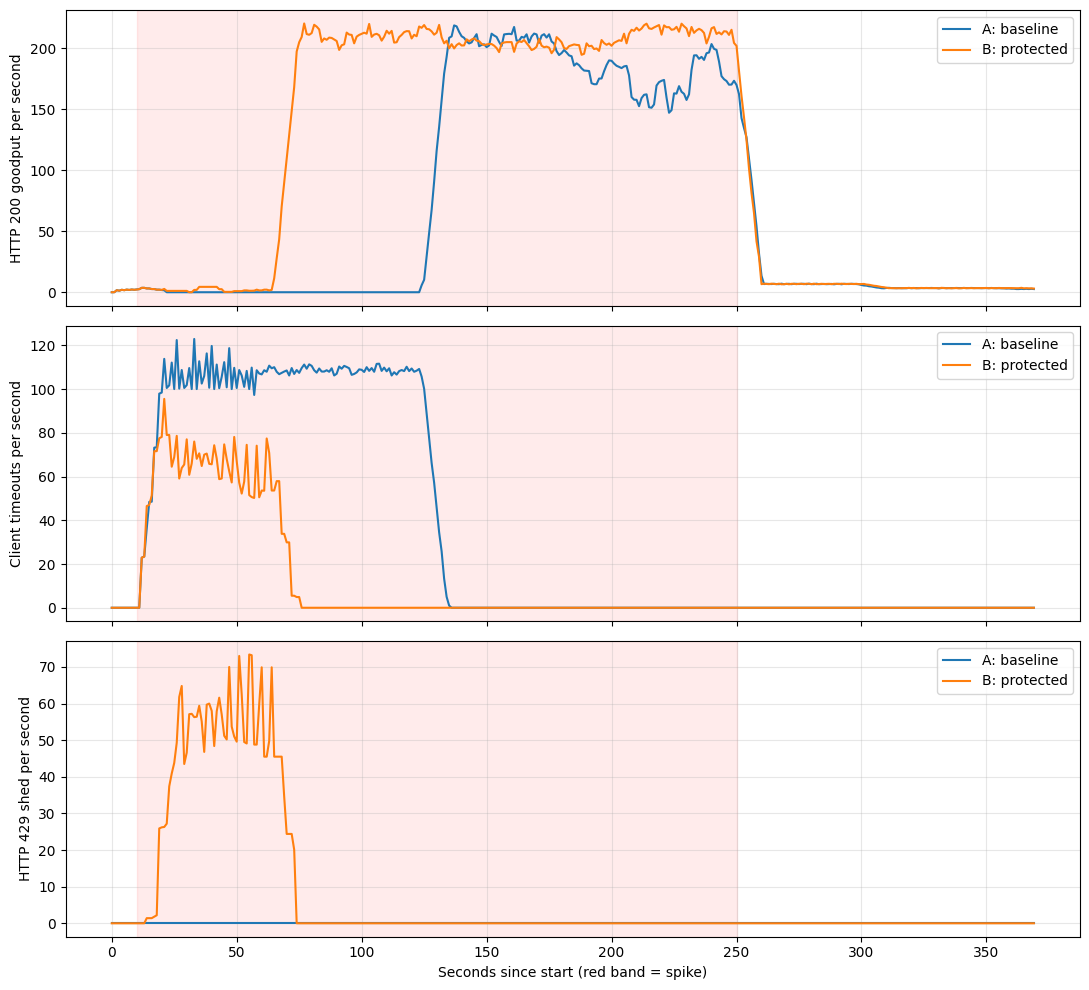

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

a = pd.read_csv('baseline2.csv')
b = pd.read_csv('protected2.csv')


def smooth(s):
    return s.rolling(10, min_periods=1).mean()


spike_start = int(a.index[a['phase'] == 'spike'][0])
spike_end = int(a.index[a['phase'] == 'post'][0])

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
panels = [('ok', 'HTTP 200 goodput per second'),
          ('timeout', 'Client timeouts per second'),
          ('shed', 'HTTP 429 shed per second')]
for ax, (col, title) in zip(axes, panels):
    ax.plot(a['second'], smooth(a[col]), label='A: baseline')
    ax.plot(b['second'], smooth(b[col]), label='B: protected')
    ax.axvspan(spike_start, spike_end, color='red', alpha=0.08)
    ax.set_ylabel(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[-1].set_xlabel('Seconds since start (red band = spike)')
plt.tight_layout()
plt.savefig('comparison2.png', dpi=150)
print('Saved comparison.png')

for name, d in [('A baseline', a), ('B protected', b)]:
    base = d[d['phase'] == 'baseline']
    spike = d[d['phase'] == 'spike']
    post = d[d['phase'] == 'post']
    target = 0.9 * base['ok'].mean()
    sm = smooth(d['ok'])
    rec = sm[(d['phase'] == 'post') & (sm >= target)]
    print(name)
    print('  goodput/s  baseline phase:', round(base['ok'].mean(), 2))
    print('  goodput/s  spike phase   :', round(spike['ok'].mean(), 2))
    print('  goodput/s  post phase    :', round(post['ok'].mean(), 2))
    print('  total 200s:', int(d['ok'].sum()), ' timeouts:', int(d['timeout'].sum()),
          ' 429s:', int(d['shed'].sum()))
    if len(rec):
        print('  recovery time after spike (s):', int(rec.index[0]) - spike_end)
    else:
        print('  recovery time after spike: did not recover')
